# Q1 — Fase 0: caracterização do dataset

Exploração **descritiva** do dataset da Q1 (estilos de jogo por role, comparados entre BR1, EUW1 e KR),
antes de qualquer tratamento. Sem inferência: tamanho, significado das colunas, nulos, quantas partidas cada
jogador tem em cada role e como as features se distribuem.

**Fontes** (ver `PLANO_Q1_CLUSTERING.md`):
- `data/player_style_features_q1.parquet`: tabela **partida × participante** (10 linhas por partida, 75 features).
- `data/cohort_challenger.csv`: fotos da coorte (Challenger + top-100 GM, de 07/set a 28/set).
- `src/features/player_role.py`: monta a tabela **jogador × role** (a unidade do clustering) a partir das duas.

**Corte:** só partidas até a última foto da Q1 usada no corpus (25/set, 06h), igual nas três regiões.

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.features import player_role as pr

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

ROLES = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]
REGIONS = ["BR1", "EUW1", "KR"]

## 1. As duas tabelas

- **Partida × participante (`coorte`)**: uma linha por jogador da coorte em cada partida, na própria região.
  É a base do ICC, do teste de estabilidade (metades no tempo) e do efeito de campeão.
- **Jogador × role (`jr`)**: uma linha por (jogador, role), com a média das partidas **naquela role**.
  Sem piso: o piso de partidas é escolhido na análise.

In [2]:
raw = pd.read_parquet(pr.features_path, columns=["match_id", "region", "cohort_region", "game_creation"])
fotos = pr.load_photos()
final_ts = pr.final_photo_times(fotos)

coorte = pr.load_matches()                     # coorte na própria região, com role
coorte = coorte[coorte["game_creation"] <= coorte["region"].map(final_ts)].reset_index(drop=True)
FEATS = pr.feature_columns(coorte)
jr = pr.build(coorte, fotos)                  # média, sem piso

print(f"partida × participante (tudo): {len(raw):,} linhas, {raw.match_id.nunique():,} partidas")
print(f"coorte até a foto final:       {len(coorte):,} linhas, {coorte.match_id.nunique():,} partidas, "
      f"{coorte.puuid.nunique():,} jogadores, {len(FEATS)} features")
print(f"jogador × role:                {len(jr):,} pares")
print("foto final por região:", final_ts.dt.strftime("%d/%m %H:%M").to_dict())

2026-09-28 19:22:48.450 | INFO     | src.features.player_role:build:131 - Partidas depois da foto final (2026-09-25), fora da tabela: {}


2026-09-28 19:22:48.488 | INFO     | src.features.player_role:build:143 - Linhas fora da janela própria, por região: {'BR1': 0.116, 'EUW1': 0.074, 'KR': 0.072}


partida × participante (tudo): 628,010 linhas, 62,801 partidas
coorte até a foto final:       206,607 linhas, 62,782 partidas, 1,365 jogadores, 75 features
jogador × role:                6,135 pares
foto final por região: {'BR1': '25/09 06:01', 'EUW1': '25/09 06:01', 'KR': '25/09 06:01'}


## 2. Tamanho do corpus

In [3]:
pc = coorte.drop_duplicates("match_id")         # uma linha por partida
g = coorte.groupby("region")
pd.DataFrame({
    "partidas no corpus": raw.drop_duplicates("match_id").groupby("region").size(),
    "partidas com jogador da coorte (até a foto final)": g.match_id.nunique(),
    "linhas da coorte": g.size(),
    "jogadores": g.puuid.nunique(),
    "jogadores da coorte por partida": (g.size() / g.match_id.nunique()).round(2),
}).T

region,BR1,EUW1,KR
partidas no corpus,18443.00,22503.00,21855.00
partidas com jogador da coorte (até a foto final),18424.00,22503.00,21855.00
linhas da coorte,57745.00,69407.00,79455.00
jogadores,370.00,506.00,489.00
jogadores da coorte por partida,3.13,3.08,3.64


In [4]:
# tier = o da última foto até a final; in_final_foto = está na foto de 25/set
jog = jr.drop_duplicates("puuid")
display(pd.crosstab(jog.region, jog.tier, margins=True, margins_name="total"))
pd.crosstab(jog.region, jog.in_final_foto, margins=True, margins_name="total")

tier,CHALLENGER,GRANDMASTER,total
region,,,
BR1,207,163,370
EUW1,319,187,506
KR,325,164,489
total,851,514,1365


in_final_foto,False,True,total
region,,,
BR1,70,300,370
EUW1,107,399,506
KR,89,400,489
total,266,1099,1365


In [5]:
# patches: fração das partidas de cada região
pd.crosstab(pc.region, pc.patch, normalize="index").round(3)

patch,16.15,16.16,16.17,16.18,16.19
region,,,,,
BR1,0.105,0.331,0.317,0.223,0.025
EUW1,0.059,0.328,0.348,0.234,0.031
KR,0.053,0.333,0.355,0.230,0.029


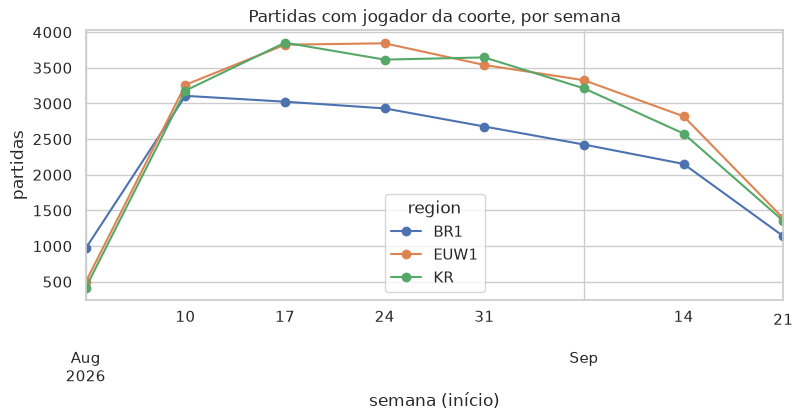

region,BR1,EUW1,KR
semana,,,
2026-08-03,969,498,417
2026-08-10,3107,3261,3180
2026-08-17,3025,3824,3853
2026-08-24,2931,3844,3615
2026-08-31,2677,3540,3646
2026-09-07,2424,3326,3212
2026-09-14,2152,2820,2578
2026-09-21,1139,1390,1354


In [6]:
sem = (pc.assign(semana=pc.game_creation.dt.tz_localize(None).dt.to_period("W").dt.start_time)
         .groupby(["semana", "region"]).size().unstack())
ax = sem.plot(marker="o", figsize=(9, 3.5))
ax.set_ylabel("partidas"); ax.set_xlabel("semana (início)")
ax.set_title("Partidas com jogador da coorte, por semana")
plt.show()
sem

## 3. Significado das colunas

Janelas: `_15` = até o frame dos 15 min; `_late` = frames depois dele (precisa de ≥3, jogo de ~18 min ou mais);
`_full` = jogo inteiro. Definição completa em `src/features/player_style_features.py`.

In [7]:
BLOCO = {
    "Combate": ["kills", "deaths", "assists", "solo_kills", "kda", "kill_participation", "first_blood"],
    "Recursos": ["cs_per_min", "jungle_cs_per_min", "gold_per_min", "xp_per_min"],
    "Dano": ["dmg_champ_per_min", "dmg_share", "dmg_taken_share"],
    "Visão": ["wards_placed_per_min", "control_wards_per_min", "ward_kills_per_min",
              "vision_score_per_min", "control_ward_coverage"],
    "Estruturas": ["turret_kills", "turret_takedowns", "plates", "first_tower",
                   "dmg_to_turrets_per_min", "quick_first_turret"],
    "Objetivos neutros": ["dragon_takedowns", "herald_takedowns", "baron_takedowns", "horde_takedowns",
                          "objective_presence", "dmg_to_objectives_per_min", "epic_monster_steals", "obj_setup"],
    "Selva": ["enemy_jungle_cs", "ally_jungle_cs", "scuttle_kills", "initial_crab"],
    "Espacial": ["pos_spread", "mean_dist_centroid", "time_in_enemy_half", "gank_roam",
                 "side_solo", "allies_near", "side_lean"],
}
POR_MIN = ["kills", "deaths", "assists", "solo_kills", "cs_per_min", "jungle_cs_per_min", "gold_per_min",
           "xp_per_min", "dmg_champ_per_min", "wards_placed_per_min", "control_wards_per_min",
           "ward_kills_per_min", "turret_kills", "turret_takedowns", "plates", "dragon_takedowns",
           "herald_takedowns", "baron_takedowns", "horde_takedowns", "vision_score_per_min",
           "dmg_to_turrets_per_min", "dmg_to_objectives_per_min", "enemy_jungle_cs", "ally_jungle_cs",
           "scuttle_kills", "epic_monster_steals"]
UNIDADE = {
    **dict.fromkeys(POR_MIN, "por minuto da janela"),
    "kda": "(K+A) / max(D, 1)",
    **dict.fromkeys(["kill_participation", "dmg_share", "dmg_taken_share"], "fração do time (0–1)"),
    **dict.fromkeys(["objective_presence", "time_in_enemy_half", "gank_roam", "side_solo", "obj_setup",
                     "control_ward_coverage"], "fração (0–1)"),
    **dict.fromkeys(["pos_spread", "mean_dist_centroid"], "unidades do mapa"),
    "allies_near": "aliados a menos de 5.000 (0–4)",
    "side_lean": "−1 (lado do bot) a +1 (lado do top)",
    **dict.fromkeys(["first_blood", "first_tower", "quick_first_turret"], "sim/não"),
    "initial_crab": "contagem (0–2)",
}
base = lambda c: re.sub(r"_(15|full|late)$", "", c)
bloco_de = {b: k for k, bs in BLOCO.items() for b in bs}
dic = pd.DataFrame({
    "feature": FEATS,
    "bloco": [bloco_de[base(c)] for c in FEATS],
    "janela": [re.search(r"_(15|full|late)$", c).group(1) for c in FEATS],
    "unidade": [UNIDADE[base(c)] for c in FEATS],
    "nulos_%": [round(100 * coorte[c].isna().mean(), 1) for c in FEATS],
})
assert len(dic) == 75
print(dic.groupby(["bloco", "janela"]).size().unstack(fill_value=0))
dic.sort_values(["bloco", "feature"]).reset_index(drop=True)

janela             15  full  late
bloco                            
Combate             7     6     1
Dano                3     3     0
Espacial            5     4     5
Estruturas          4     4     0
Objetivos neutros   5     8     0
Recursos            4     4     0
Selva               0     4     0
Visão               3     5     0


,feature,bloco,janela,unidade,nulos_%
0,assists_15,Combate,15,por minuto da janela,0.0
1,assists_full,Combate,full,por minuto da janela,0.0
2,deaths_15,Combate,15,por minuto da janela,0.0
3,deaths_full,Combate,full,por minuto da janela,0.0
4,first_blood_15,Combate,15,sim/não,0.0
5,kda_15,Combate,15,"(K+A) / max(D, 1)",0.0
6,kda_full,Combate,full,"(K+A) / max(D, 1)",0.0
7,kill_participation_15,Combate,15,fração do time (0–1),0.0
8,kill_participation_full,Combate,full,fração do time (0–1),0.0
9,kill_participation_late,Combate,late,fração do time (0–1),12.0


## 4. Duração das partidas e janela `_late`

,count,mean,std,min,10%,25%,50%,75%,90%,max
region,,,,,,,,,,
BR1,18424.0,27.2,6.1,10.0,18.9,23.5,27.2,31.1,34.8,56.8
EUW1,22503.0,26.8,6.0,10.0,18.6,23.2,26.7,30.6,34.3,58.1
KR,21855.0,24.8,6.3,10.2,15.4,19.8,24.9,29.2,32.8,52.5


region
BR1     0.924
EUW1    0.920
KR      0.835
Name: fração com janela _late, dtype: float64

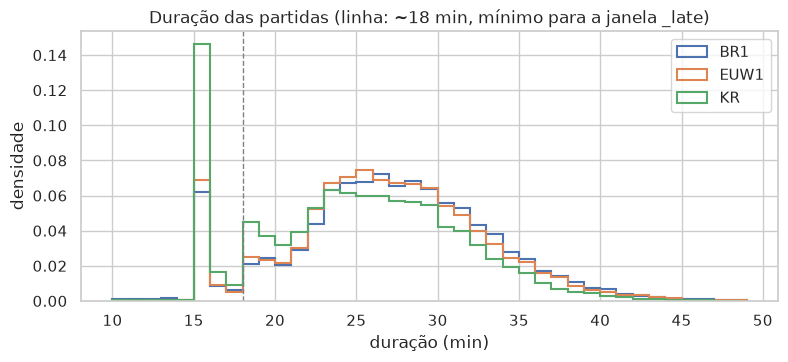

In [8]:
d = pc.assign(tem_late=pc["pos_spread_late"].notna())
display(d.groupby("region").game_duration_min.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
display(d.groupby("region").tem_late.mean().round(3).rename("fração com janela _late"))
fig, ax = plt.subplots(figsize=(9, 3.5))
for r in REGIONS:
    ax.hist(d.loc[d.region == r, "game_duration_min"], bins=np.arange(10, 50, 1), histtype="step", lw=1.5,
            density=True, label=r)
ax.axvline(18, ls="--", c="gray", lw=1)
ax.set_xlabel("duração (min)"); ax.set_ylabel("densidade"); ax.legend()
ax.set_title("Duração das partidas (linha: ~18 min, mínimo para a janela _late)")
plt.show()

## 5. Nulos

Nulo aqui é sempre estrutural (a medida não existe naquela partida ou role); nenhum vem de falha de extração.

In [9]:
MOTIVO = {
    "_late": "partida sem ≥3 frames depois dos 15 min (jogo de menos de ~18 min)",
    "gank_roam": "jungle: não tem rota (por construção); laner: nenhum abate/assistência na janela",
    "side_lean_15": "nenhum frame fora da faixa da mid entre 3 e 15 min",
    "control_ward_coverage_full": "campo ausente no `challenges` (sem control ward, ou sem cobertura no rio/lado inimigo)",
    "kill_participation": "time sem abates na janela",
    "objective_presence_15": "nenhum objetivo até os 15 min",
    "obj_setup_full": "nenhum monstro épico com frame 30 s antes",
    "scuttle_kills_full": "campo ausente no `challenges`",
    "epic_monster_steals_full": "campo ausente no `challenges`",
}
def motivo(c):
    for k, v in MOTIVO.items():
        if k in c:
            return v
    return ""
nul = coorte.groupby("role")[FEATS].apply(lambda x: x.isna().mean() * 100).T[ROLES]
nul = nul[nul.max(axis=1) > 0].round(2)
nul["motivo"] = [motivo(c) for c in nul.index]
nul.sort_values("TOP", ascending=False)

role,TOP,JUNGLE,MIDDLE,BOTTOM,UTILITY,motivo
control_ward_coverage_full,51.93,27.08,45.79,57.51,7.35,campo ausente no `challenges` (sem control war...
kill_participation_late,12.12,12.14,11.49,11.97,12.72,partida sem ≥3 frames depois dos 15 min (jogo ...
allies_near_late,11.56,11.61,10.93,11.41,12.15,partida sem ≥3 frames depois dos 15 min (jogo ...
time_in_enemy_half_late,11.56,11.61,10.93,11.41,12.15,partida sem ≥3 frames depois dos 15 min (jogo ...
mean_dist_centroid_late,11.56,11.61,10.93,11.41,12.15,partida sem ≥3 frames depois dos 15 min (jogo ...
pos_spread_late,11.56,11.61,10.93,11.41,12.15,partida sem ≥3 frames depois dos 15 min (jogo ...
side_solo_late,11.56,11.61,10.93,11.41,12.15,partida sem ≥3 frames depois dos 15 min (jogo ...
gank_roam_15,6.58,100.00,2.98,2.20,0.54,jungle: não tem rota (por construção); laner: ...
gank_roam_full,1.41,100.00,0.76,0.54,0.20,jungle: não tem rota (por construção); laner: ...
kill_participation_full,0.01,0.02,0.01,0.01,0.01,time sem abates na janela


In [10]:
# control_ward_coverage_full: nulo × ter posto alguma control ward (fração nula em cada grupo)
cw = coorte.assign(nulo=coorte.control_ward_coverage_full.isna(),
                   poe_control_ward=coorte.control_wards_per_min_full > 0)
display(cw.groupby(["role", "poe_control_ward"]).nulo.mean().unstack().loc[ROLES].rename(columns={False: "sem control ward", True: "com control ward"}).round(3))
print("zeros exatos entre os não nulos:", int((coorte.control_ward_coverage_full == 0).sum()))

poe_control_ward,sem control ward,com control ward
role,,
TOP,1.0,0.136
JUNGLE,1.0,0.098
MIDDLE,1.0,0.114
BOTTOM,1.0,0.205
UTILITY,1.0,0.040


zeros exatos entre os não nulos: 0


## 6. Partidas por (jogador, role)

`n_matches` = partidas do jogador naquela role; `frac_role` = fração das partidas dele que são nessa role;
role principal = a de mais partidas.

In [11]:
main = jr[jr.is_main_role]
q = [.1, .25, .5, .75, .9]
display(main.groupby("region").n_matches.describe(percentiles=q).round(0).rename_axis("partidas na role principal"))
display(main.groupby("region").frac_role.describe(percentiles=q).round(2).rename_axis("fração na role principal"))
(main.frac_role >= .9).groupby(main.region).mean().round(3).rename("fração de jogadores com ≥90% numa role")

,count,mean,std,min,10%,25%,50%,75%,90%,max
partidas na role principal,,,,,,,,,,
BR1,370.0,115.0,79.0,13.0,35.0,50.0,98.0,154.0,221.0,520.0
EUW1,506.0,101.0,72.0,9.0,32.0,45.0,82.0,134.0,198.0,437.0
KR,489.0,123.0,94.0,16.0,36.0,49.0,95.0,164.0,273.0,500.0


,count,mean,std,min,10%,25%,50%,75%,90%,max
fração na role principal,,,,,,,,,,
BR1,370.0,0.73,0.15,0.30,0.52,0.64,0.75,0.84,0.91,0.96
EUW1,506.0,0.74,0.14,0.30,0.56,0.65,0.76,0.85,0.92,1.00
KR,489.0,0.76,0.12,0.33,0.62,0.69,0.76,0.85,0.91,1.00


region
BR1     0.116
EUW1    0.134
KR      0.127
Name: fração de jogadores com ≥90% numa role, dtype: float64

In [12]:
# pares (jogador, role) que passam cada piso — só a role principal × todas as roles
tabs = {}
for piso in (20, 30, 50):
    tabs[(piso, "principal")] = pr.count_by_role(jr, piso, main_only=True)
    tabs[(piso, "todas")] = pr.count_by_role(jr, piso, main_only=False)
pd.concat(tabs, axis=1).loc[ROLES + ["total"]]

20                                              30                                              50                                      
        principal                 todas                 principal                 todas                 principal                 todas                
region        BR1 EUW1   KR total   BR1 EUW1   KR total       BR1 EUW1   KR total   BR1 EUW1   KR total       BR1 EUW1   KR total   BR1 EUW1   KR total
role                                                                                                                                                   
TOP            51   61   86   198   116  131  143   390        48   59   85   192    70   90  110   270        40   45   71   156    48   58   80   186
JUNGLE         73   94  103   270    93  107  148   348        67   90  101   258    78   97  128   303        56   71   79   206    61   75   85   221
MIDDLE        114  172  122   408   156  193  164   513       107  154  113   374   125  161  132   418        82  120   86   288    90  123   94   307
BOTTOM         81  126  109   316   147  203  158   508        78  117  106   301   117  155  133   405        63   92   79   234    77   98   86   261
UTILITY        48   47   66   161    78   82  160   320        48   47   64   159    60   59  122   241        39   36   49   124    45   40   66   151
total         367  500  486  1353   590  716  773  2079       348  467  469  1284   450  562  625  1637       280  364  364  1008   321  394  411  1126

In [13]:
# flex: pares que passam o piso de 30 fora da role principal
flex = jr[(jr.n_matches >= 30) & ~jr.is_main_role]
display(pd.crosstab(flex.role, flex.region, margins=True, margins_name="total"))
jr[jr.n_matches >= 30].groupby("is_main_role").autofill_rate.describe().round(3)

region,BR1,EUW1,KR,total
role,,,,
BOTTOM,39,38,27,104
JUNGLE,11,7,27,45
MIDDLE,18,7,19,44
TOP,22,31,25,78
UTILITY,12,12,58,82
total,102,95,156,353


,count,mean,std,min,25%,50%,75%,max
is_main_role,,,,,,,,
False,353.0,0.251,0.362,0.0,0.0,0.043,0.422,1.000
True,1284.0,0.003,0.019,0.0,0.0,0.000,0.000,0.347


In [14]:
# sensibilidade: só quem está na foto final (piso 30, role principal)
pd.concat({"qualquer foto": pr.count_by_role(jr, 30),
           "só foto final": pr.count_by_role(jr[jr.in_final_foto], 30)}, axis=1).loc[ROLES + ["total"]]

qualquer foto                 só foto final                
region            BR1 EUW1   KR total           BR1 EUW1   KR total
role                                                               
TOP                48   59   85   192            40   43   63   146
JUNGLE             67   90  101   258            51   70   81   202
MIDDLE            107  154  113   374            87  128   99   314
BOTTOM             78  117  106   301            69   97   89   255
UTILITY            48   47   64   159            41   37   55   133
total             348  467  469  1284           288  375  387  1050

In [15]:
# cobertura: fração das partidas do par dentro da janela própria (primeira foto − 30 dias até a última foto)
# e fração das partidas com janela _late (piso 30)
j30 = jr[jr.n_matches >= 30]
display(j30.groupby("region").frac_own_window.describe(percentiles=q).round(3))
(j30.n_late / j30.n_matches).groupby(j30.region).describe(percentiles=q).round(3)

,count,mean,std,min,10%,25%,50%,75%,90%,max
region,,,,,,,,,,
BR1,450.0,0.884,0.160,0.107,0.641,0.813,0.965,1.0,1.0,1.0
EUW1,562.0,0.930,0.114,0.351,0.762,0.886,1.000,1.0,1.0,1.0
KR,625.0,0.935,0.110,0.435,0.783,0.914,1.000,1.0,1.0,1.0


,count,mean,std,min,10%,25%,50%,75%,90%,max
region,,,,,,,,,,
BR1,450.0,0.916,0.039,0.657,0.869,0.892,0.921,0.942,0.963,1.000
EUW1,562.0,0.915,0.036,0.769,0.871,0.893,0.917,0.938,0.961,1.000
KR,625.0,0.838,0.047,0.656,0.781,0.812,0.839,0.867,0.900,0.977


## 7. Distribuições das features

Primeiro na partida (todas as linhas da coorte), depois no jogador × role (piso 30), que é a unidade do clustering.

In [16]:
# mediana por role, nível partida
med = coorte.groupby("role")[FEATS].median().T[ROLES]
med.insert(0, "bloco", [bloco_de[base(c)] for c in med.index])
med.sort_values("bloco").round(3)

role,bloco,TOP,JUNGLE,MIDDLE,BOTTOM,UTILITY
kills_15,Combate,0.133,0.200,0.200,0.200,0.067
kills_full,Combate,0.184,0.261,0.234,0.253,0.070
deaths_15,Combate,0.133,0.133,0.133,0.200,0.200
deaths_full,Combate,0.196,0.177,0.187,0.207,0.214
assists_15,Combate,0.067,0.200,0.133,0.133,0.400
assists_full,Combate,0.180,0.287,0.214,0.246,0.526
kda_15,Combate,1.500,3.250,2.000,2.000,2.667
kda_full,Combate,2.000,3.333,2.625,2.571,3.000
kill_participation_15,Combate,0.273,0.500,0.375,0.429,0.562
kill_participation_full,Combate,0.379,0.558,0.467,0.500,0.600


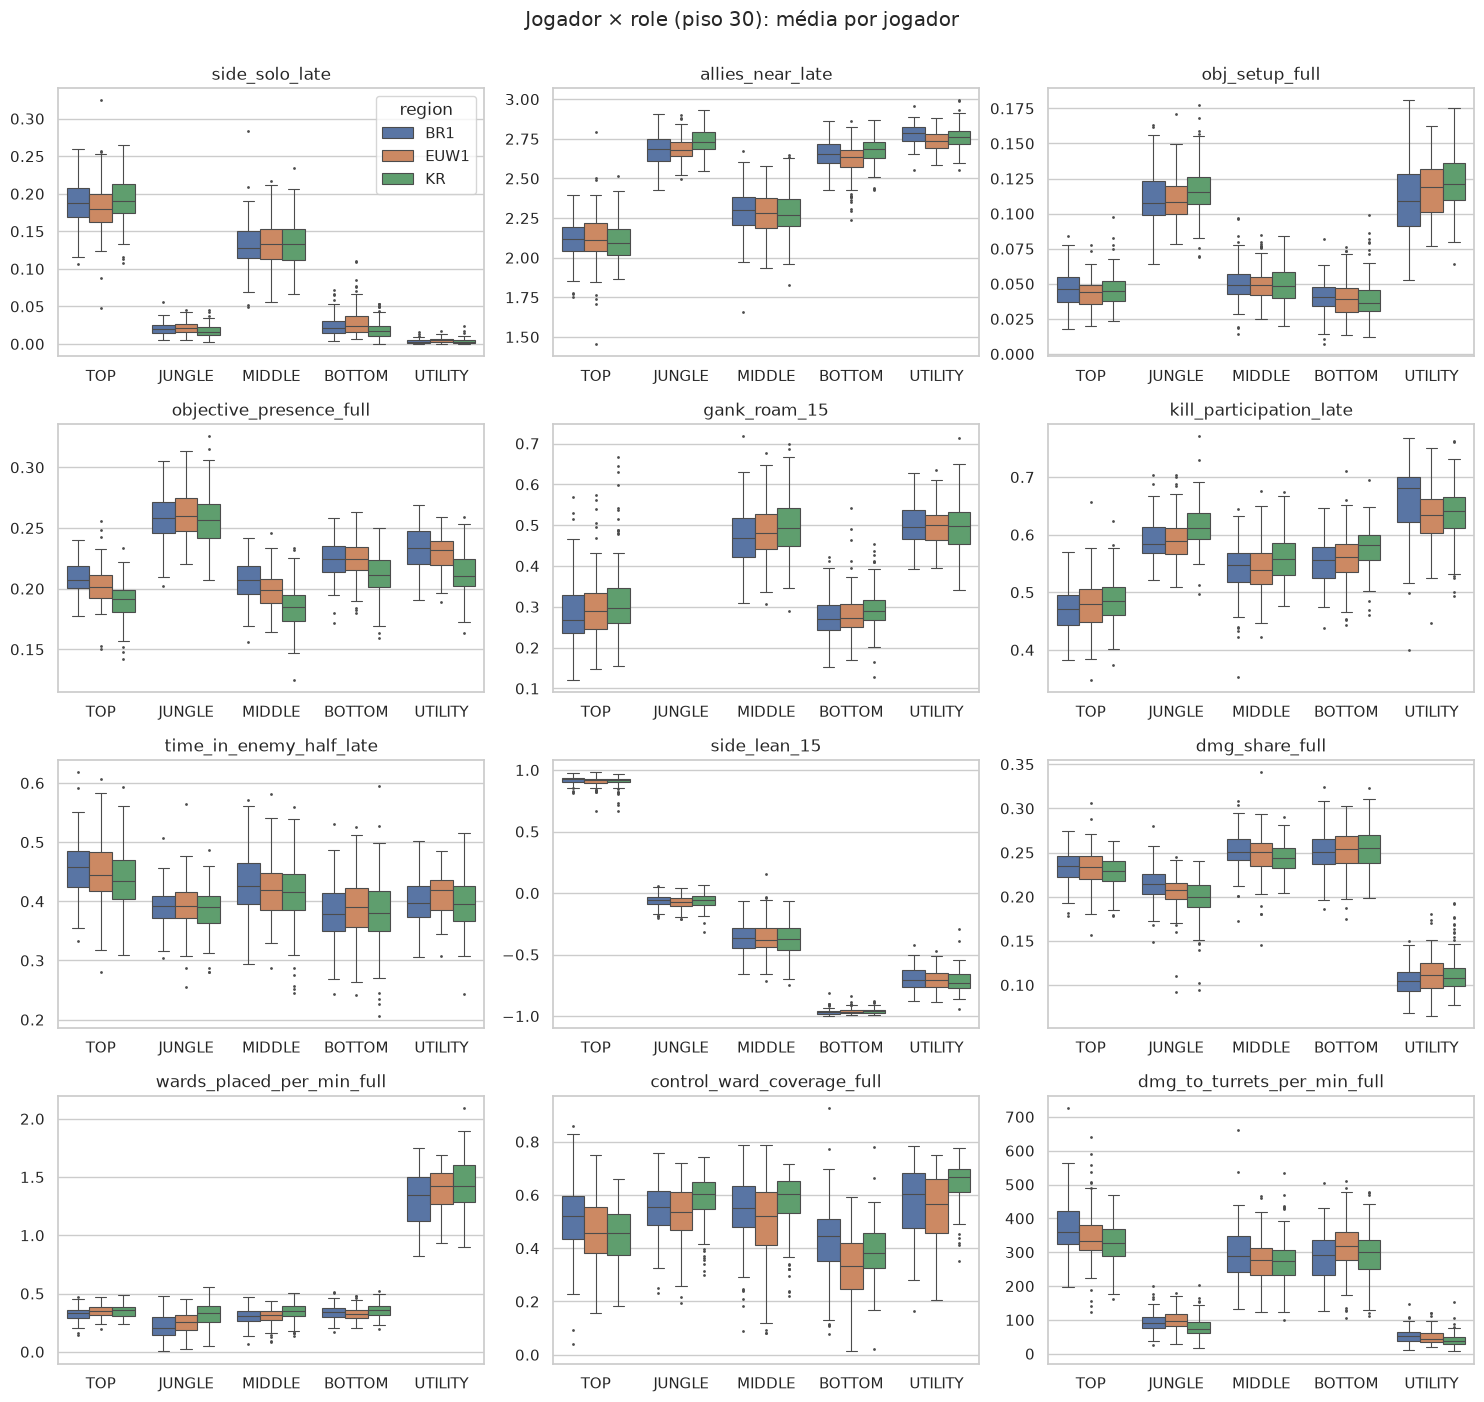

In [17]:
FOCO = ["side_solo_late", "allies_near_late", "obj_setup_full", "objective_presence_full", "gank_roam_15",
        "kill_participation_late", "time_in_enemy_half_late", "side_lean_15", "dmg_share_full",
        "wards_placed_per_min_full", "control_ward_coverage_full", "dmg_to_turrets_per_min_full"]
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, f in zip(axes.flat, FOCO):
    sns.boxplot(data=j30, x="role", y=f, hue="region", order=ROLES, hue_order=REGIONS,
                fliersize=1, linewidth=.8, ax=ax)
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
fig.suptitle("Jogador × role (piso 30): média por jogador", y=1.0)
plt.tight_layout(); plt.show()

In [18]:
# mediana por role × região, nível jogador × role (piso 30)
j30.groupby(["role", "region"])[FOCO].median().loc[ROLES].round(3)

side_solo_late  allies_near_late  obj_setup_full  objective_presence_full  gank_roam_15  kill_participation_late  time_in_enemy_half_late  side_lean_15  dmg_share_full  \
role    region                                                                                                                                                                            
TOP     BR1              0.187             2.117           0.046                    0.207         0.269                    0.471                    0.458         0.924           0.234   
        EUW1             0.180             2.113           0.044                    0.202         0.290                    0.479                    0.445         0.916           0.234   
        KR               0.191             2.094           0.045                    0.191         0.298                    0.485                    0.435         0.917           0.229   
JUNGLE  BR1              0.020             2.683           0.108                    0.258           NaN                    0.584                    0.393        -0.059           0.214   
        EUW1             0.021             2.679           0.108                    0.260           NaN                    0.589                    0.392        -0.075           0.208   
        KR               0.016             2.732           0.115                    0.256           NaN                    0.611                    0.390        -0.056           0.200   
MIDDLE  BR1              0.128             2.302           0.049                    0.207         0.470                    0.547                    0.425        -0.367           0.250   
        EUW1             0.133             2.281           0.049                    0.199         0.480                    0.540                    0.419        -0.379           0.250   
        KR               0.133             2.271           0.048                    0.185         0.494                    0.557                    0.416        -0.371           0.244   
BOTTOM  BR1              0.022             2.653           0.041                    0.224         0.271                    0.555                    0.378        -0.970           0.251   
        EUW1             0.023             2.638           0.039                    0.224         0.272                    0.562                    0.391        -0.963           0.254   
        KR               0.017             2.685           0.036                    0.211         0.289                    0.581                    0.381        -0.961           0.255   
UTILITY BR1              0.003             2.789           0.109                    0.234         0.495                    0.680                    0.397        -0.706           0.105   
        EUW1             0.005             2.734           0.119                    0.232         0.501                    0.634                    0.419        -0.703           0.111   
        KR               0.003             2.763           0.121                    0.210         0.499                    0.642                    0.396        -0.727           0.107   

                wards_placed_per_min_full  control_ward_coverage_full  dmg_to_turrets_per_min_full  
role    region                                                                                      
TOP     BR1                         0.334                       0.523                      359.198  
        EUW1                        0.353                       0.458                      333.971  
        KR                          0.361                       0.456                      326.389  
JUNGLE  BR1                         0.208                       0.554                       91.672  
        EUW1                        0.260                       0.537                       98.254  
        KR                          0.334                       0.605                       73.227  
MIDDLE  BR1                 

## 8. Para a Fase 1

O que a Fase 1 (`q1_fase1.ipynb`) faz, com critérios fixados **antes** de olhar clusters (plano, seção 3):
1. agregação (média; mediana como checagem nas contínuas de cauda longa);
2. ICC por feature e role (variação entre jogadores × entre partidas);
3. grupos: estilo (entra), habilidade/resultado (descreve), contexto;
4. redundância (correlação, VIF; `_15` + `_late` em vez de `_full` onde há as três);
5. transformação (log nas taxas assimétricas; z-score dentro da role);
6. resultado: tabela feature × role com entra/sai e o motivo.

**Observações da Fase 0:**
-